
# DS605 Lab Assignment 8
## Decision Trees and Support Vector Machines

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

print("Libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)


Libraries imported successfully!
NumPy version: 2.1.3
Pandas version: 2.2.3


In [2]:



import pandas as pd

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00267/data_banknote_authentication.txt"
)

columns = [
    "Variance",
    "Skewness",
    "Curtosis",
    "Entropy",
    "Class"
]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (1372, 5)


,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [3]:


print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of rows and columns:")
print(df.shape)


First 5 rows:


,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Column names:
['Variance', 'Skewness', 'Curtosis', 'Entropy', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Missing values in each column:
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64

Number of rows and columns:
(1372, 5)


In [4]:

print("Class distribution:")
print(df["Class"].value_counts().sort_index())

print("\nClass distribution in percentages:")
print((df["Class"].value_counts(normalize=True).sort_index() * 100).round(2))


Class distribution:
Class
0    762
1    610
Name: count, dtype: int64

Class distribution in percentages:
Class
0    55.54
1    44.46
Name: proportion, dtype: float64


In [5]:
df.describe().round(3)

,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000,1372.000,1372.000,1372.000,1372.000
mean,0.434,1.922,1.398,-1.192,0.445
std,2.843,5.869,4.310,2.101,0.497
min,-7.042,-13.773,-5.286,-8.548,0.000
25%,-1.773,-1.708,-1.575,-2.413,0.000
50%,0.496,2.320,0.617,-0.587,0.000
75%,2.821,6.815,3.179,0.395,1.000
max,6.825,12.952,17.927,2.450,1.000


In [6]:

X = df[["Variance", "Skewness", "Curtosis", "Entropy"]]
y = df["Class"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", sorted(y.unique()))


Input features shape: (1372, 4)
Target shape: (1372,)
Classes: [np.int64(0), np.int64(1)]


In [7]:


X_2d = df[["Variance", "Skewness"]]
y = df["Class"]

print("Two-feature dataset shape:", X_2d.shape)
print("Target shape:", y.shape)


Two-feature dataset shape: (1372, 2)
Target shape: (1372,)


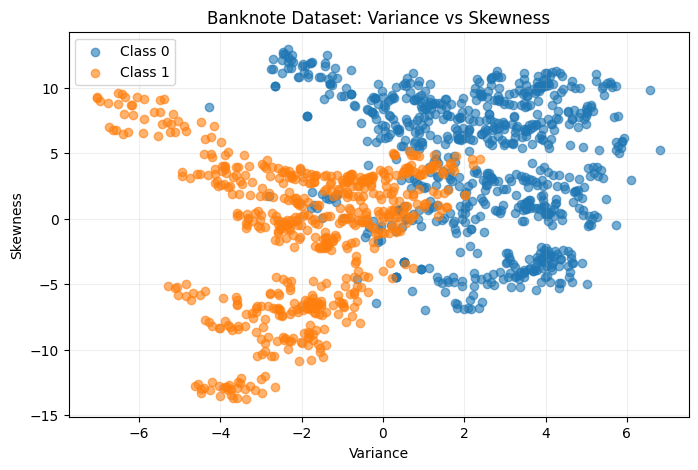

In [9]:

plt.figure(figsize=(8, 5))

for class_value in sorted(y.unique()):
    subset = df[df["Class"] == class_value]

    plt.scatter(
        subset["Variance"],
        subset["Skewness"],
        label=f"Class {class_value}",
        alpha=0.6
    )

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Banknote Dataset: Variance vs Skewness")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [10]:

import numpy as np

def gini_impurity(y):

    _, counts = np.unique(y, return_counts=True)


    probabilities = counts / len(y)


    gini = 1 - np.sum(probabilities ** 2)

    return gini



pure_group = np.array([0, 0, 0, 0, 0])


mixed_group = np.array([0, 0, 1, 1])

print("Gini of pure group:", gini_impurity(pure_group))
print("Gini of mixed group:", gini_impurity(mixed_group))


Gini of pure group: 0.0
Gini of mixed group: 0.5


In [11]:

def entropy(y):

    _, counts = np.unique(y, return_counts=True)


    probabilities = counts / len(y)

    probabilities = probabilities[probabilities > 0]

    result = -np.sum(
        probabilities * np.log2(probabilities)
    )

    return result


print("Entropy of pure group:",
      entropy(np.array([0, 0, 0, 0, 0])))


print("Entropy of mixed group:",
      entropy(np.array([0, 0, 1, 1])))


Entropy of pure group: -0.0
Entropy of mixed group: 1.0


In [13]:

def split_data(X, y, feature_index, threshold):
    # Divide the samples into left and right groups
    left_mask = X[:, feature_index] <= threshold
    right_mask = ~left_mask

    X_left = X[left_mask]
    y_left = y[left_mask]

    X_right = X[right_mask]
    y_right = y[right_mask]

    return X_left, y_left, X_right, y_right


def weighted_gini(y_left, y_right):
    # Total number of samples
    total = len(y_left) + len(y_right)

    # Weighted impurity of both groups
    score = (
        (len(y_left) / total) * gini_impurity(y_left)
        + (len(y_right) / total) * gini_impurity(y_right)
    )

    return score


In [14]:

X_example = np.array([
    [1.0, 2.0],
    [1.5, 2.5],
    [3.0, 3.5],
    [3.5, 4.0]
])

y_example = np.array([0, 0, 1, 1])


X_left, y_left, X_right, y_right = split_data(
    X_example, y_example, feature_index=0, threshold=2.0
)

print("Left group labels:", y_left)
print("Right group labels:", y_right)
print("Weighted Gini:", weighted_gini(y_left, y_right))


Left group labels: [0 0]
Right group labels: [1 1]
Weighted Gini: 0.0


In [15]:

def find_best_split(X, y):
    best_gini = float("inf")
    best_feature = None
    best_threshold = None

    n_features = X.shape[1]

    # Try every feature
    for feature_index in range(n_features):

        # Try thresholds between unique feature values
        values = np.unique(X[:, feature_index])

        if len(values) < 2:
            continue

        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            X_left, y_left, X_right, y_right = split_data(
                X, y, feature_index, threshold
            )

            # Ignore splits that create an empty group
            if len(y_left) == 0 or len(y_right) == 0:
                continue

            score = weighted_gini(y_left, y_right)

            # Keep the best split found so far
            if score < best_gini:
                best_gini = score
                best_feature = feature_index
                best_threshold = threshold

    return best_feature, best_threshold, best_gini


In [16]:

feature, threshold, score = find_best_split(
    X_example, y_example
)

print("Best feature index:", feature)
print("Best threshold:", threshold)
print("Best weighted Gini:", score)


Best feature index: 0
Best threshold: 2.25
Best weighted Gini: 0.0


In [17]:

def majority_class(y):
    classes, counts = np.unique(y, return_counts=True)
    return classes[np.argmax(counts)]


def build_tree(X, y, depth=0, max_depth=3):
    # Store the most common class as the fallback prediction
    node = {
        "prediction": majority_class(y),
        "feature": None,
        "threshold": None,
        "left": None,
        "right": None
    }

    # Stop if the node is pure or maximum depth is reached
    if len(np.unique(y)) == 1 or depth >= max_depth:
        return node

    # Find the best split
    feature, threshold, score = find_best_split(X, y)

    # Stop if no valid split exists
    if feature is None:
        return node

    # Divide the data using the chosen split
    X_left, y_left, X_right, y_right = split_data(
        X, y, feature, threshold
    )

    # Save the split rule
    node["feature"] = feature
    node["threshold"] = threshold

    # Build both branches recursively
    node["left"] = build_tree(
        X_left, y_left, depth + 1, max_depth
    )
    node["right"] = build_tree(
        X_right, y_right, depth + 1, max_depth
    )

    return node


In [18]:

small_tree = build_tree(
    X_example,
    y_example,
    max_depth=3
)

print("Learned root feature:", small_tree["feature"])
print("Learned root threshold:", small_tree["threshold"])
print("Left child prediction:", small_tree["left"]["prediction"])
print("Right child prediction:", small_tree["right"]["prediction"])


Learned root feature: 0
Learned root threshold: 2.25
Left child prediction: 0
Right child prediction: 1


In [19]:

def predict_one(node, sample):

    if node["feature"] is None:
        return node["prediction"]


    feature = node["feature"]
    threshold = node["threshold"]

    if sample[feature] <= threshold:
        return predict_one(node["left"], sample)
    else:
        return predict_one(node["right"], sample)


def predict_tree(tree, X):

    predictions = []

    for sample in X:
        prediction = predict_one(tree, sample)
        predictions.append(prediction)

    return np.array(predictions)


In [20]:


example_predictions = predict_tree(small_tree, X_example)

print("Actual classes:    ", y_example)
print("Predicted classes: ", example_predictions)

print(
    "All predictions correct:",
    np.array_equal(y_example, example_predictions)
)


Actual classes:     [0 0 1 1]
Predicted classes:  [0 0 1 1]
All predictions correct: True


In [21]:

from sklearn.model_selection import train_test_split


X_2d = df[["Variance", "Skewness"]].to_numpy()
y = df["Class"].to_numpy()


X_train, X_test, y_train, y_test = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)


Training samples: 1097
Testing samples: 275
Training feature shape: (1097, 2)
Testing feature shape: (275, 2)


In [22]:

manual_tree = build_tree(
    X_train,
    y_train,
    max_depth=5
)


y_pred_manual = predict_tree(manual_tree, X_test)

print("First 10 actual labels:    ", y_test[:10])
print("First 10 predicted labels: ", y_pred_manual[:10])


First 10 actual labels:     [0 1 0 1 1 1 0 0 0 1]
First 10 predicted labels:  [0 1 0 1 1 1 0 0 0 1]


In [23]:

correct_predictions = np.sum(y_test == y_pred_manual)
accuracy = correct_predictions / len(y_test)

print("Correct predictions:", correct_predictions)
print("Total test samples:", len(y_test))
print("Manual Decision Tree accuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")


Correct predictions: 256
Total test samples: 275
Manual Decision Tree accuracy: 0.9309
Accuracy percentage: 93.09 %


In [24]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Train a Scikit-learn Decision Tree
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

sklearn_tree.fit(X_train, y_train)

# Predict the same test samples
y_pred_sklearn = sklearn_tree.predict(X_test)

# Calculate accuracy
sklearn_accuracy = accuracy_score(y_test, y_pred_sklearn)

print("Manual tree accuracy:",
      round(accuracy_score(y_test, y_pred_manual) * 100, 2), "%")

print("Scikit-learn tree accuracy:",
      round(sklearn_accuracy * 100, 2), "%")


Manual tree accuracy: 93.09 %
Scikit-learn tree accuracy: 93.09 %


In [25]:

# Comparing the two implementations

same_predictions = np.sum(y_pred_manual == y_pred_sklearn)
different_predictions = np.sum(y_pred_manual != y_pred_sklearn)

print("Same predictions:", same_predictions)
print("Different predictions:", different_predictions)
print("Total test samples:", len(y_test))


Same predictions: 275
Different predictions: 0
Total test samples: 275


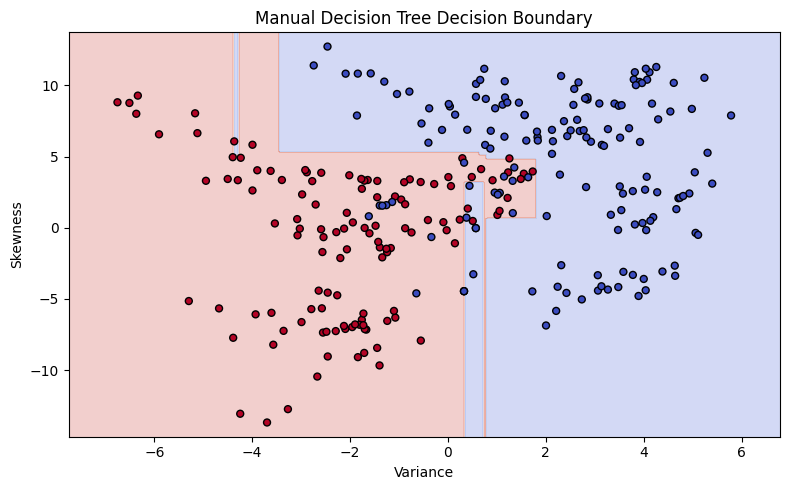

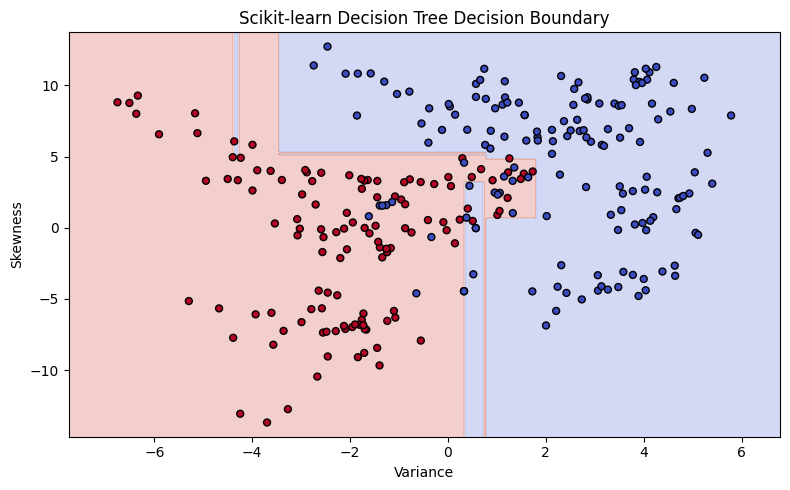

In [26]:

# Plot the manual and Scikit-learn Decision Tree boundaries

def plot_tree_boundary(model_predict, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model_predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", s=25
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.tight_layout()
    plt.show()


# Manual tree
plot_tree_boundary(
    lambda data: predict_tree(manual_tree, data),
    X_test, y_test,
    "Manual Decision Tree Decision Boundary"
)

# Scikit-learn tree
plot_tree_boundary(
    sklearn_tree.predict,
    X_test, y_test,
    "Scikit-learn Decision Tree Decision Boundary"
)


In [27]:

def print_tree(node, feature_names, depth=0):
    indent = "  " * depth

    # If the node is a leaf, print its prediction
    if node["feature"] is None:
        print(f"{indent}Predict Class {node['prediction']}")
        return

    feature_name = feature_names[node["feature"]]
    threshold = node["threshold"]

    print(f"{indent}IF {feature_name} <= {threshold:.4f}:")
    print_tree(node["left"], feature_names, depth + 1)

    print(f"{indent}ELSE:")
    print_tree(node["right"], feature_names, depth + 1)


feature_names = ["Variance", "Skewness"]

print_tree(manual_tree, feature_names)


IF Variance <= 0.7651:
  IF Skewness <= 5.1608:
    IF Variance <= 0.3202:
      IF Variance <= -0.4586:
        IF Skewness <= 0.0548:
          Predict Class 1
        ELSE:
          Predict Class 1
      ELSE:
        IF Skewness <= -0.1666:
          Predict Class 1
        ELSE:
          Predict Class 1
    ELSE:
      IF Skewness <= 3.2197:
        IF Variance <= 0.7406:
          Predict Class 0
        ELSE:
          Predict Class 1
      ELSE:
        Predict Class 1
  ELSE:
    IF Variance <= -3.4311:
      IF Variance <= -4.3819:
        Predict Class 1
      ELSE:
        IF Variance <= -4.2554:
          Predict Class 0
        ELSE:
          Predict Class 1
    ELSE:
      IF Skewness <= 5.3646:
        IF Variance <= 0.6458:
          Predict Class 1
        ELSE:
          Predict Class 0
      ELSE:
        Predict Class 0
ELSE:
  IF Variance <= 1.7907:
    IF Skewness <= 4.8814:
      IF Skewness <= 0.6642:
        IF Skewness <= 0.1376:
          Predict Class 0


In [28]:

# Study the effect of maximum tree depth

depth_results = []

for depth in [1, 2, 3, 5, 10]:
    tree = build_tree(
        X_train,
        y_train,
        max_depth=depth
    )

    train_predictions = predict_tree(tree, X_train)
    test_predictions = predict_tree(tree, X_test)

    train_accuracy = np.mean(train_predictions == y_train)
    test_accuracy = np.mean(test_predictions == y_test)

    depth_results.append({
        "Max Depth": depth,
        "Train Accuracy": round(train_accuracy, 4),
        "Test Accuracy": round(test_accuracy, 4)
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df)


,Max Depth,Train Accuracy,Test Accuracy
0,1,0.8423,0.8291
1,2,0.9015,0.8764
2,3,0.9289,0.9091
3,5,0.9480,0.9309
4,10,0.9954,0.9200


In [29]:

def calculate_impurity(y, criterion="gini"):
    if criterion == "gini":
        return gini_impurity(y)

    elif criterion == "entropy":
        return entropy(y)

    else:
        raise ValueError(
            "Criterion must be 'gini' or 'entropy'."
        )


def weighted_impurity(y_left, y_right, criterion="gini"):
    total = len(y_left) + len(y_right)

    return (
        len(y_left) / total
        * calculate_impurity(y_left, criterion)
        + len(y_right) / total
        * calculate_impurity(y_right, criterion)
    )


In [30]:

def find_best_split(X, y, criterion="gini"):
    best_score = float("inf")
    best_feature = None
    best_threshold = None

    for feature_index in range(X.shape[1]):
        values = np.unique(X[:, feature_index])

        if len(values) < 2:
            continue

        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            _, y_left, _, y_right = split_data(
                X, y, feature_index, threshold
            )

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            score = weighted_impurity(
                y_left, y_right, criterion
            )

            if score < best_score:
                best_score = score
                best_feature = feature_index
                best_threshold = threshold

    return best_feature, best_threshold, best_score


In [31]:

def build_tree(X, y, depth=0, max_depth=3, criterion="gini"):
    node = {
        "prediction": majority_class(y),
        "feature": None,
        "threshold": None,
        "left": None,
        "right": None
    }

    if len(np.unique(y)) == 1 or depth >= max_depth:
        return node

    feature, threshold, score = find_best_split(
        X, y, criterion
    )

    if feature is None:
        return node

    X_left, y_left, X_right, y_right = split_data(
        X, y, feature, threshold
    )

    node["feature"] = feature
    node["threshold"] = threshold

    node["left"] = build_tree(
        X_left, y_left, depth + 1, max_depth, criterion
    )

    node["right"] = build_tree(
        X_right, y_right, depth + 1, max_depth, criterion
    )

    return node


In [32]:

# Compare Gini and entropy on the same test set

criterion_results = []

for criterion in ["gini", "entropy"]:
    tree = build_tree(
        X_train,
        y_train,
        max_depth=5,
        criterion=criterion
    )

    predictions = predict_tree(tree, X_test)
    accuracy = np.mean(predictions == y_test)

    criterion_results.append({
        "Criterion": criterion,
        "Max Depth": 5,
        "Test Accuracy": round(accuracy, 4)
    })

display(pd.DataFrame(criterion_results))


,Criterion,Max Depth,Test Accuracy
0,gini,5,0.9309
1,entropy,5,0.9345


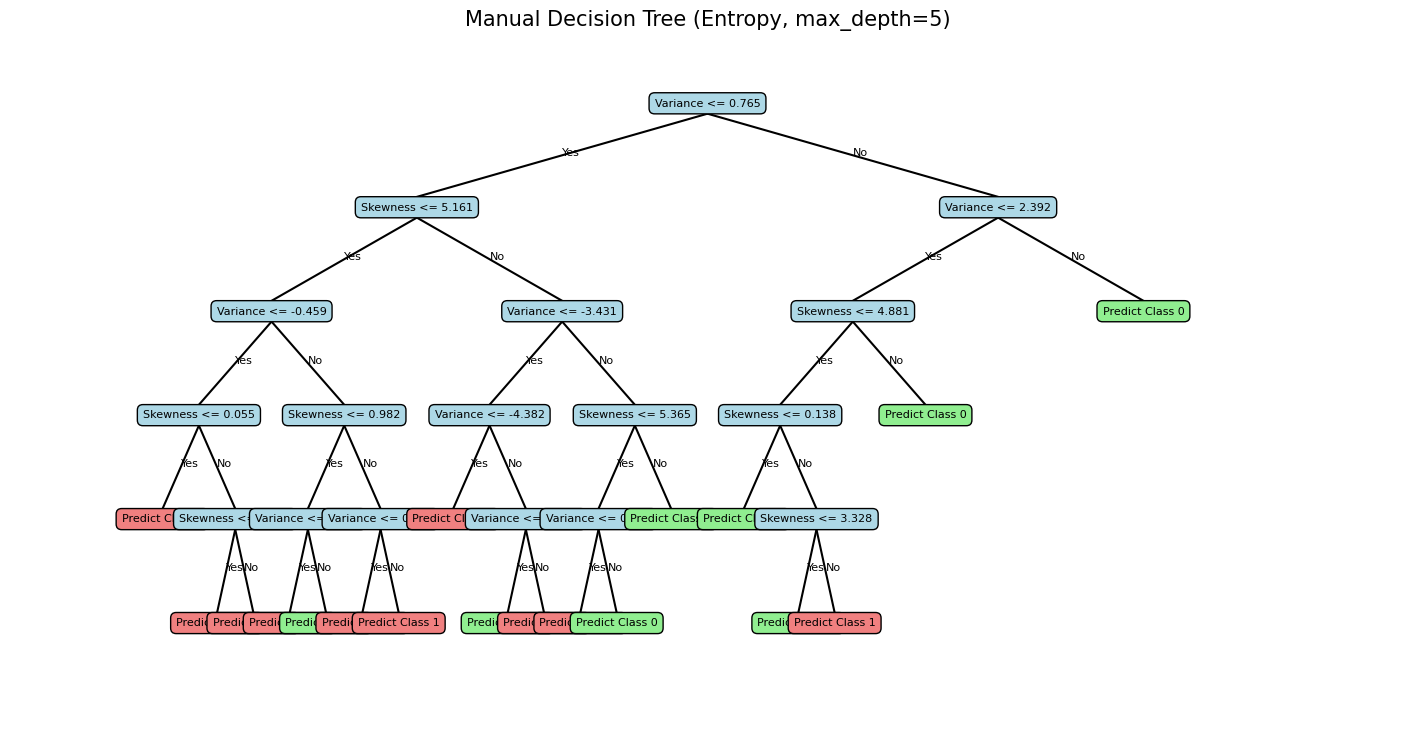

In [33]:

def draw_manual_tree(node, feature_names, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(18, 9))
        ax.axis("off")
        ax.set_title(
            "Manual Decision Tree (Entropy, max_depth=5)",
            fontsize=15
        )

    def add_node(current, x, y, dx, depth):
        if current["feature"] is None:
            label = f"Predict Class {current['prediction']}"
            color = "lightgreen" if current["prediction"] == 0 else "lightcoral"
        else:
            feature = feature_names[current["feature"]]
            label = f"{feature} <= {current['threshold']:.3f}"
            color = "lightblue"

        ax.text(
            x, y, label,
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fc=color, ec="black"),
            fontsize=8
        )

        if current["feature"] is not None:
            child_y = y - 1.5
            left_x = x - dx
            right_x = x + dx

            ax.plot([x, left_x], [y - 0.15, child_y + 0.15], "k-")
            ax.plot([x, right_x], [y - 0.15, child_y + 0.15], "k-")

            ax.text((x + left_x) / 2, (y + child_y) / 2,
                    "Yes", fontsize=8)
            ax.text((x + right_x) / 2, (y + child_y) / 2,
                    "No", fontsize=8)

            add_node(current["left"], left_x, child_y, dx / 2, depth + 1)
            add_node(current["right"], right_x, child_y, dx / 2, depth + 1)

    add_node(node, 0, 0, 5, 0)
    ax.set_xlim(-12, 12)
    ax.set_ylim(-9, 1)
    plt.show()


entropy_tree = build_tree(
    X_train, y_train, max_depth=5, criterion="entropy"
)

draw_manual_tree(entropy_tree, ["Variance", "Skewness"])


In [34]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

comparison = []

for criterion in ["gini", "entropy"]:
    # Manual implementation
    manual = build_tree(
        X_train, y_train,
        max_depth=5,
        criterion=criterion
    )
    manual_pred = predict_tree(manual, X_test)

    # Scikit-learn implementation
    sklearn_model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=5,
        random_state=42
    )
    sklearn_model.fit(X_train, y_train)
    sklearn_pred = sklearn_model.predict(X_test)

    comparison.append({
        "Criterion": criterion,
        "Manual Accuracy": round(accuracy_score(y_test, manual_pred), 4),
        "Scikit-learn Accuracy": round(accuracy_score(y_test, sklearn_pred), 4),
        "Matching Predictions": int(np.sum(manual_pred == sklearn_pred))
    })

display(pd.DataFrame(comparison))


,Criterion,Manual Accuracy,Scikit-learn Accuracy,Matching Predictions
0,gini,0.9309,0.9309,275
1,entropy,0.9345,0.9345,275


In [35]:

# Preparing the two-feature data for our manual SVM

# Calculating statistics from training data only
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

# Avoiding division by zero if a feature has no variation
X_std[X_std == 0] = 1

# Standardize training and test features
X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Converting labels: class 0 -> -1, class 1 -> +1
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)
print("SVM labels:", np.unique(y_train_svm))
print("Training feature means:", X_train_scaled.mean(axis=0).round(4))
print("Training feature standard deviations:",
      X_train_scaled.std(axis=0).round(4))


Scaled training shape: (1097, 2)
Scaled test shape: (275, 2)
SVM labels: [-1  1]
Training feature means: [-0. -0.]
Training feature standard deviations: [1. 1.]


In [36]:

def hinge_loss(y_true, scores):
    # Calculate the margin for each sample
    margins = y_true * scores

    # Calculate hinge loss
    losses = np.maximum(0, 1 - margins)

    # Return the average loss
    return np.mean(losses)


# Test the function with three examples
print("Outside margin:", hinge_loss(
    np.array([1]), np.array([2.0])
))

print("Inside margin:", hinge_loss(
    np.array([1]), np.array([0.5])
))

print("Incorrect prediction:", hinge_loss(
    np.array([1]), np.array([-1.0])
))


Outside margin: 0.0
Inside margin: 0.5
Incorrect prediction: 2.0


In [37]:

import numpy as np

# One example with two features
sample = np.array([1.0, 2.0])

# Temporary weights and bias
weights = np.array([0.5, -0.2])
bias = 0.1

# Calculate the SVM score
score = np.dot(weights, sample) + bias

print("SVM score:", score)


SVM score: 0.19999999999999998


In [38]:

sample = np.array([1.0, 4.0])

score = np.dot(weights, sample) + bias

print("SVM score:", score)

if score > 0:
    print("Predicted class: +1")
elif score < 0:
    print("Predicted class: -1")
else:
    print("On the decision boundary")


SVM score: -0.20000000000000004
Predicted class: -1


In [39]:

def svm_objective_one(sample, true_label, weights, bias, lam=0.1):
    score = np.dot(weights, sample) + bias

    hinge = max(0, 1 - true_label * score)
    regularization = (lam / 2) * np.sum(weights ** 2)

    total_loss = hinge + regularization

    return score, hinge, regularization, total_loss


sample = np.array([1.0, 2.0])
true_label = 1

score, hinge, reg, total = svm_objective_one(
    sample, true_label, weights, bias
)

print("Score:", score)
print("Hinge loss:", hinge)
print("Regularization:", reg)
print("Total objective:", total)


Score: 0.19999999999999998
Hinge loss: 0.8
Regularization: 0.014500000000000002
Total objective: 0.8145


In [40]:

sample = np.array([1.0, 4.0])
true_label = 1

score, hinge, reg, total = svm_objective_one(
    sample, true_label, weights, bias
)

print("Score:", score)
print("Hinge loss:", hinge)
print("Regularization:", reg)
print("Total objective:", total)


Score: -0.20000000000000004
Hinge loss: 1.2
Regularization: 0.014500000000000002
Total objective: 1.2145


In [41]:

# Current weights and bias
weights = np.array([0.5, -0.2], dtype=float)
bias = 0.1

# One training example
sample = np.array([1.0, 4.0])
true_label = 1

# Learning rate
learning_rate = 0.01

# Calculate the score and margin
score = np.dot(weights, sample) + bias
margin = true_label * score

print("Before update - score:", score)
print("Before update - margin:", margin)

# Update when the example violates the margin
if margin < 1:
    weights = weights + learning_rate * true_label * sample
    bias = bias + learning_rate * true_label

print("Updated weights:", weights)
print("Updated bias:", bias)

# Check the new score
new_score = np.dot(weights, sample) + bias
print("After update - score:", new_score)


Before update - score: -0.20000000000000004
Before update - margin: -0.20000000000000004
Updated weights: [ 0.51 -0.16]
Updated bias: 0.11
After update - score: -0.020000000000000004


In [42]:

new_score = np.dot(weights, sample) + bias

new_hinge_loss = max(0, 1 - true_label * new_score)

print("Updated score:", new_score)
print("Updated hinge loss:", new_hinge_loss)


Updated score: -0.020000000000000004
Updated hinge loss: 1.02


In [43]:

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Train a linear SVM using the scaled training data
svm_model = LinearSVC(C=1.0, max_iter=10000, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test_scaled)

# Evaluate the model
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("Linear SVM Test Accuracy:", round(svm_accuracy, 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))


Linear SVM Test Accuracy: 0.8764

Confusion Matrix:
[[135  18]
 [ 16 106]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.89       153
           1       0.85      0.87      0.86       122

    accuracy                           0.88       275
   macro avg       0.87      0.88      0.87       275
weighted avg       0.88      0.88      0.88       275



In [44]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


X_full = df[["Variance", "Skewness", "Curtosis", "Entropy"]].to_numpy()
y_full = df["Class"].to_numpy()

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)


scaler_full = StandardScaler()
X_train_full_scaled = scaler_full.fit_transform(X_train_full)
X_test_full_scaled = scaler_full.transform(X_test_full)

print("Full dataset shape:", X_full.shape)
print("Training features:", X_train_full.shape)
print("Testing features:", X_test_full.shape)
print("Feature names:", ["Variance", "Skewness", "Curtosis", "Entropy"])
print("Training class labels:", sorted(set(y_train_full)))


Full dataset shape: (1372, 4)
Training features: (1097, 4)
Testing features: (275, 4)
Feature names: ['Variance', 'Skewness', 'Curtosis', 'Entropy']
Training class labels: [np.int64(0), np.int64(1)]


In [45]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import time

# Model 1: Decision Tree using all four features
tree_full = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    random_state=42
)

start = time.perf_counter()
tree_full.fit(X_train_full, y_train_full)
tree_train_time = time.perf_counter() - start

tree_predictions_full = tree_full.predict(X_test_full)
tree_accuracy_full = accuracy_score(y_test_full, tree_predictions_full)


# Model 2: Linear SVM using scaled features
svm_full = LinearSVC(
    C=1.0,
    max_iter=10000,
    random_state=42
)

start = time.perf_counter()
svm_full.fit(X_train_full_scaled, y_train_full)
svm_train_time = time.perf_counter() - start

svm_predictions_full = svm_full.predict(X_test_full_scaled)
svm_accuracy_full = accuracy_score(y_test_full, svm_predictions_full)


# Compare results
comparison = pd.DataFrame({
    "Model": ["Decision Tree (Entropy)", "Linear SVM"],
    "Test Accuracy": [tree_accuracy_full, svm_accuracy_full],
    "Training Time (seconds)": [tree_train_time, svm_train_time]
})

print(comparison.to_string(index=False))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test_full, tree_predictions_full))

print("\nLinear SVM Classification Report:")
print(classification_report(y_test_full, svm_predictions_full))


                  Model  Test Accuracy  Training Time (seconds)
Decision Tree (Entropy)       0.985455                 0.007250
             Linear SVM       0.985455                 0.003739

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       153
           1       0.98      0.99      0.98       122

    accuracy                           0.99       275
   macro avg       0.98      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275


Linear SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99       153
           1       0.97      1.00      0.98       122

    accuracy                           0.99       275
   macro avg       0.98      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



In [46]:

tree_wrong = tree_predictions_full != y_test_full
svm_wrong = svm_predictions_full != y_test_full

print("Decision Tree mistakes:", tree_wrong.sum())
print("Linear SVM mistakes:", svm_wrong.sum())

print("Mistakes made by both models:",
      (tree_wrong & svm_wrong).sum())

print("Mistakes made only by Decision Tree:",
      (tree_wrong & ~svm_wrong).sum())

print("Mistakes made only by Linear SVM:",
      (~tree_wrong & svm_wrong).sum())


Decision Tree mistakes: 4
Linear SVM mistakes: 4
Mistakes made by both models: 0
Mistakes made only by Decision Tree: 4
Mistakes made only by Linear SVM: 4


In [47]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time

# Creating an SVM with an RBF kernel
rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

# Training the model
start = time.perf_counter()
rbf_svm.fit(X_train_full_scaled, y_train_full)
rbf_train_time = time.perf_counter() - start

# Making predictions
rbf_predictions = rbf_svm.predict(X_test_full_scaled)

# Evaluating
rbf_accuracy = accuracy_score(y_test_full, rbf_predictions)

print("RBF SVM Test Accuracy:", round(rbf_accuracy, 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_full, rbf_predictions))

print("\nClassification Report:")
print(classification_report(y_test_full, rbf_predictions))

print("Training time (seconds):", round(rbf_train_time, 6))


RBF SVM Test Accuracy: 1.0

Confusion Matrix:
[[153   0]
 [  0 122]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       153
           1       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275

Training time (seconds): 0.012026


In [48]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time

# Creating a polynomial-kernel SVM
poly_svm = SVC(
    kernel="poly",
    degree=3,
    C=1.0,
    gamma="scale"
)

# Training the model
start = time.perf_counter()
poly_svm.fit(X_train_full_scaled, y_train_full)
poly_train_time = time.perf_counter() - start

# Predicting test labels
poly_predictions = poly_svm.predict(X_test_full_scaled)

# Evaluating the model
poly_accuracy = accuracy_score(y_test_full, poly_predictions)

print("Polynomial SVM Test Accuracy:", round(poly_accuracy, 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_full, poly_predictions))

print("\nClassification Report:")
print(classification_report(y_test_full, poly_predictions))

print("Training time (seconds):", round(poly_train_time, 6))


Polynomial SVM Test Accuracy: 0.9818

Confusion Matrix:
[[148   5]
 [  0 122]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       153
           1       0.96      1.00      0.98       122

    accuracy                           0.98       275
   macro avg       0.98      0.98      0.98       275
weighted avg       0.98      0.98      0.98       275

Training time (seconds): 0.025249


In [49]:

final_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree (Entropy)",
        "Linear SVM",
        "RBF SVM",
        "Polynomial SVM"
    ],
    "Test Accuracy": [
        tree_accuracy_full,
        svm_accuracy_full,
        rbf_accuracy,
        poly_accuracy
    ],
    "Training Time (seconds)": [
        tree_train_time,
        svm_train_time,
        rbf_train_time,
        poly_train_time
    ]
})

final_comparison = final_comparison.sort_values(
    by="Test Accuracy", ascending=False
).reset_index(drop=True)

print(final_comparison.to_string(
    index=False,
    formatters={
        "Test Accuracy": "{:.4f}".format,
        "Training Time (seconds)": "{:.6f}".format
    }
))


                  Model Test Accuracy Training Time (seconds)
                RBF SVM        1.0000                0.012026
Decision Tree (Entropy)        0.9855                0.007250
             Linear SVM        0.9855                0.003739
         Polynomial SVM        0.9818                0.025249


In [50]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd
import time

C_values = [0.1, 1, 10, 100]
C_results = []

for c_value in C_values:
    model = SVC(
        kernel="rbf",
        C=c_value,
        gamma="scale"
    )

    start = time.perf_counter()
    model.fit(X_train_full_scaled, y_train_full)
    elapsed = time.perf_counter() - start

    predictions = model.predict(X_test_full_scaled)
    accuracy = accuracy_score(y_test_full, predictions)

    C_results.append({
        "C": c_value,
        "Test Accuracy": accuracy,
        "Training Time (seconds)": elapsed
    })

C_results_df = pd.DataFrame(C_results)

print(C_results_df.to_string(
    index=False,
    formatters={
        "Test Accuracy": "{:.4f}".format,
        "Training Time (seconds)": "{:.6f}".format
    }
))


    C Test Accuracy Training Time (seconds)
  0.1        0.9855                0.026528
  1.0        1.0000                0.011211
 10.0        1.0000                0.009280
100.0        1.0000                0.008713


In [51]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd
import time

gamma_values = [0.01, 0.1, 1, 10]
gamma_results = []

for gamma_value in gamma_values:
    model = SVC(
        kernel="rbf",
        C=1.0,
        gamma=gamma_value
    )

    start = time.perf_counter()
    model.fit(X_train_full_scaled, y_train_full)
    elapsed = time.perf_counter() - start

    predictions = model.predict(X_test_full_scaled)
    accuracy = accuracy_score(y_test_full, predictions)

    gamma_results.append({
        "Gamma": gamma_value,
        "Test Accuracy": accuracy,
        "Training Time (seconds)": elapsed
    })

gamma_results_df = pd.DataFrame(gamma_results)

print(gamma_results_df.to_string(
    index=False,
    formatters={
        "Test Accuracy": "{:.4f}".format,
        "Training Time (seconds)": "{:.6f}".format
    }
))


 Gamma Test Accuracy Training Time (seconds)
  0.01        0.9709                0.037296
  0.10        0.9964                0.012391
  1.00        1.0000                0.012241
 10.00        1.0000                0.080421


In [52]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select the two features required for decision-boundary plots
X_2d = df[["Variance", "Skewness"]].to_numpy(dtype=float)
y_2d = df["Class"].to_numpy()

# Create a consistent train-test split
X_train_svm, X_test_svm, y_train_svm_original, y_test_svm_original = (
    train_test_split(
        X_2d,
        y_2d,
        test_size=0.2,
        random_state=42,
        stratify=y_2d
    )
)

# Scale using training data only
svm_scaler = StandardScaler()
X_train_svm_scaled = svm_scaler.fit_transform(X_train_svm)
X_test_svm_scaled = svm_scaler.transform(X_test_svm)

# Convert labels from 0/1 to -1/+1
y_train_svm = np.where(y_train_svm_original == 0, -1, 1)
y_test_svm = np.where(y_test_svm_original == 0, -1, 1)

print("Training shape:", X_train_svm_scaled.shape)
print("Testing shape:", X_test_svm_scaled.shape)
print("Training labels:", np.unique(y_train_svm))
print("Training feature means:", X_train_svm_scaled.mean(axis=0).round(4))
print("Training feature standard deviations:",
      X_train_svm_scaled.std(axis=0).round(4))


Training shape: (1097, 2)
Testing shape: (275, 2)
Training labels: [-1  1]
Training feature means: [-0. -0.]
Training feature standard deviations: [1. 1.]


In [53]:

import time
import numpy as np

def train_linear_svm(X, y, C=1.0, learning_rate=0.01,
                     n_iterations=1000):
    n_samples, n_features = X.shape


    w = np.zeros(n_features)
    b = 0.0
    losses = []

    start_time = time.perf_counter()

    for iteration in range(n_iterations):

        scores = X @ w + b


        margins = y * scores


        active = margins < 1


        hinge_losses = np.maximum(0, 1 - margins)
        objective = (
            0.5 * np.dot(w, w)
            + C * np.mean(hinge_losses)
        )
        losses.append(objective)


        grad_w = w - (C / n_samples) * (
            X[active].T @ y[active]
        )
        grad_b = -(C / n_samples) * np.sum(y[active])


        w -= learning_rate * grad_w
        b -= learning_rate * grad_b

    training_time = time.perf_counter() - start_time

    return w, b, losses, training_time


manual_svm_weights, manual_svm_bias, svm_losses, svm_training_time = (
    train_linear_svm(
        X_train_svm_scaled,
        y_train_svm,
        C=1.0,
        learning_rate=0.01,
        n_iterations=1000
    )
)


train_scores = X_train_svm_scaled @ manual_svm_weights + manual_svm_bias
test_scores = X_test_svm_scaled @ manual_svm_weights + manual_svm_bias

y_train_manual_pred = np.where(train_scores >= 0, 1, -1)
y_test_manual_pred = np.where(test_scores >= 0, 1, -1)

train_accuracy = np.mean(y_train_manual_pred == y_train_svm)
test_accuracy = np.mean(y_test_manual_pred == y_test_svm)

print("Learned weights:", manual_svm_weights)
print("Learned bias:", manual_svm_bias)
print("Initial objective:", svm_losses[0])
print("Final recorded objective:", svm_losses[-1])
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Testing accuracy: {test_accuracy:.4f}")
print(f"Training time: {svm_training_time:.6f} seconds")


Learned weights: [-0.4985531  -0.25996625]
Learned bias: -0.2861075660893316
Initial objective: 1.0
Final recorded objective: 0.6867734302894655
Training accuracy: 0.8450
Testing accuracy: 0.8655
Training time: 0.168300 seconds


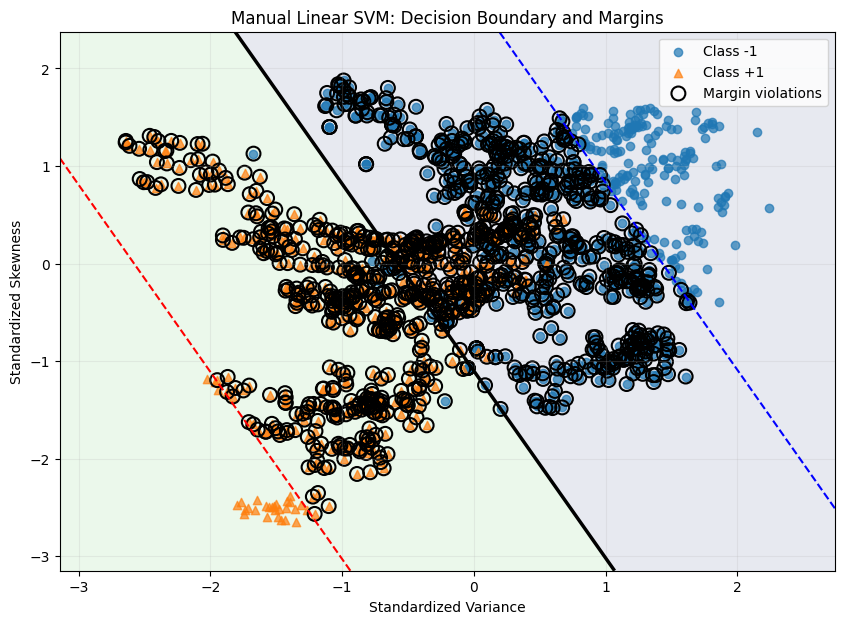

Total plotted samples: 1372
Margin-violating samples: 1163
Margin violation rate: 84.77%


In [54]:

import matplotlib.pyplot as plt

# Combine training and test data for visualization
X_plot = np.vstack((X_train_svm_scaled, X_test_svm_scaled))
y_plot = np.concatenate((y_train_svm, y_test_svm))

# Calculate each point's decision score
scores_plot = X_plot @ manual_svm_weights + manual_svm_bias

# A margin violation occurs when y * score < 1
margin_violations = y_plot * scores_plot < 1

# Create a grid for drawing the lines
x_min, x_max = X_plot[:, 0].min() - 0.5, X_plot[:, 0].max() + 0.5
y_min, y_max = X_plot[:, 1].min() - 0.5, X_plot[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scores = (
    grid @ manual_svm_weights + manual_svm_bias
).reshape(xx.shape)

plt.figure(figsize=(10, 7))

# Show class regions
plt.contourf(
    xx, yy, grid_scores,
    levels=[-100, 0, 100],
    alpha=0.12
)

# Draw the -1, 0, and +1 score lines
plt.contour(
    xx, yy, grid_scores,
    levels=[-1, 0, 1],
    colors=["blue", "black", "red"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2.5, 1.5]
)

# Plot both classes
plt.scatter(
    X_plot[y_plot == -1, 0],
    X_plot[y_plot == -1, 1],
    label="Class -1",
    marker="o",
    alpha=0.7
)

plt.scatter(
    X_plot[y_plot == 1, 0],
    X_plot[y_plot == 1, 1],
    label="Class +1",
    marker="^",
    alpha=0.7
)

# Highlight margin-violating samples
plt.scatter(
    X_plot[margin_violations, 0],
    X_plot[margin_violations, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Margin violations"
)

plt.xlabel("Standardized Variance")
plt.ylabel("Standardized Skewness")
plt.title("Manual Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Total plotted samples:", len(X_plot))
print("Margin-violating samples:", np.sum(margin_violations))
print("Margin violation rate:",
      f"{np.mean(margin_violations) * 100:.2f}%")


In [55]:

# Classification errors among all plotted samples
all_predictions = np.where(scores_plot >= 0, 1, -1)

classification_errors = all_predictions != y_plot

print("Total samples:", len(y_plot))
print("Classification errors:", np.sum(classification_errors))
print(
    "Classification error rate:",
    f"{np.mean(classification_errors) * 100:.2f}%"
)
print("Margin violations:", np.sum(margin_violations))
print("Correctly classified but within margin:",
      np.sum(margin_violations & ~classification_errors))


Total samples: 1372
Classification errors: 207
Classification error rate: 15.09%
Margin violations: 1163
Correctly classified but within margin: 956


In [56]:

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import time

# Train scikit-learn's Linear SVM
sklearn_svm = LinearSVC(
    C=1.0,
    max_iter=10000,
    random_state=42
)

start_time = time.perf_counter()
sklearn_svm.fit(X_train_svm_scaled, y_train_svm)
sklearn_training_time = time.perf_counter() - start_time

# Predictions
manual_pred = y_test_manual_pred
sklearn_pred = sklearn_svm.predict(X_test_svm_scaled)

# Compare metrics
def show_metrics(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * len(name))
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, pos_label=1):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, pos_label=1):.4f}")
    print(f"F1-score:  {f1_score(y_true, y_pred, pos_label=1):.4f}")

show_metrics("Manual NumPy Linear SVM", y_test_svm, manual_pred)
show_metrics("Scikit-learn LinearSVC", y_test_svm, sklearn_pred)

print(f"\nManual training time: {svm_training_time:.6f} seconds")
print(f"Scikit-learn training time: {sklearn_training_time:.6f} seconds")
print("Predictions identical:",
      np.array_equal(manual_pred, sklearn_pred))

print("\nScikit-learn classification report:")
print(classification_report(y_test_svm, sklearn_pred))



Manual NumPy Linear SVM
-----------------------
Accuracy:  0.8655
Precision: 0.9208
Recall:    0.7623
F1-score:  0.8341

Scikit-learn LinearSVC
----------------------
Accuracy:  0.8764
Precision: 0.8548
Recall:    0.8689
F1-score:  0.8618

Manual training time: 0.168300 seconds
Scikit-learn training time: 0.009819 seconds
Predictions identical: False

Scikit-learn classification report:
              precision    recall  f1-score   support

          -1       0.89      0.88      0.89       153
           1       0.85      0.87      0.86       122

    accuracy                           0.88       275
   macro avg       0.87      0.88      0.87       275
weighted avg       0.88      0.88      0.88       275



In [57]:

C_values = [0.01, 0.1, 1, 10, 100]

print(f"{'C':>8} {'Accuracy':>12} {'Precision':>12} {'Recall':>12} {'F1-score':>12}")
print("-" * 60)

for c_value in C_values:
    model = LinearSVC(
        C=c_value,
        max_iter=10000,
        random_state=42
    )
    model.fit(X_train_svm_scaled, y_train_svm)

    predictions = model.predict(X_test_svm_scaled)

    print(
        f"{c_value:>8.2f} "
        f"{accuracy_score(y_test_svm, predictions):>12.4f} "
        f"{precision_score(y_test_svm, predictions, pos_label=1):>12.4f} "
        f"{recall_score(y_test_svm, predictions, pos_label=1):>12.4f} "
        f"{f1_score(y_test_svm, predictions, pos_label=1):>12.4f}"
    )


       C     Accuracy    Precision       Recall     F1-score
------------------------------------------------------------
    0.01       0.8909       0.8833       0.8689       0.8760
    0.10       0.8764       0.8548       0.8689       0.8618
    1.00       0.8764       0.8548       0.8689       0.8618
   10.00       0.8764       0.8548       0.8689       0.8618
  100.00       0.8764       0.8548       0.8689       0.8618


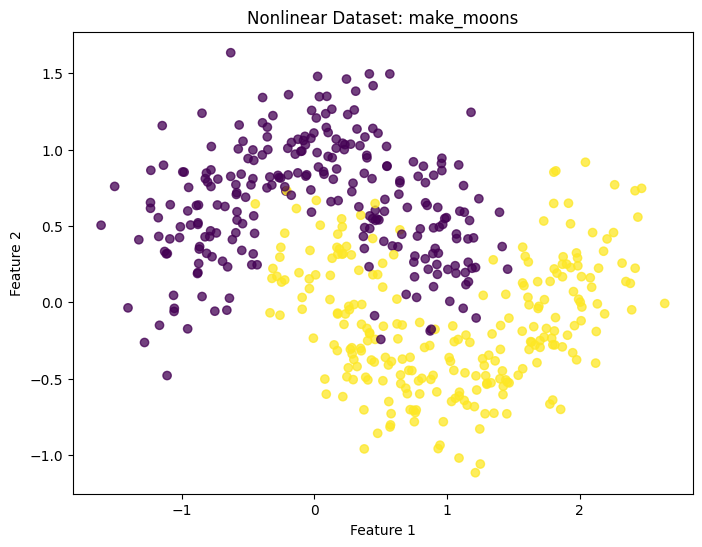

Dataset shape: (500, 2)
Training shape: (400, 2)
Testing shape: (100, 2)
Classes: {np.int64(0), np.int64(1)}


In [58]:

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Generate a nonlinear two-class dataset
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.25,
    random_state=42
)

# Split into training and testing sets
X_moons_train, X_moons_test, y_moons_train, y_moons_test = (
    train_test_split(
        X_moons,
        y_moons,
        test_size=0.2,
        random_state=42,
        stratify=y_moons
    )
)

# Visualize the complete dataset
plt.figure(figsize=(8, 6))
plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    alpha=0.75
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset: make_moons")
plt.show()

print("Dataset shape:", X_moons.shape)
print("Training shape:", X_moons_train.shape)
print("Testing shape:", X_moons_test.shape)
print("Classes:", set(y_moons))


Linear SVM: Accuracy = 0.8300, Training time = 0.005086 seconds
Polynomial SVM: Accuracy = 0.8600, Training time = 0.004298 seconds
RBF SVM: Accuracy = 0.9400, Training time = 0.003044 seconds


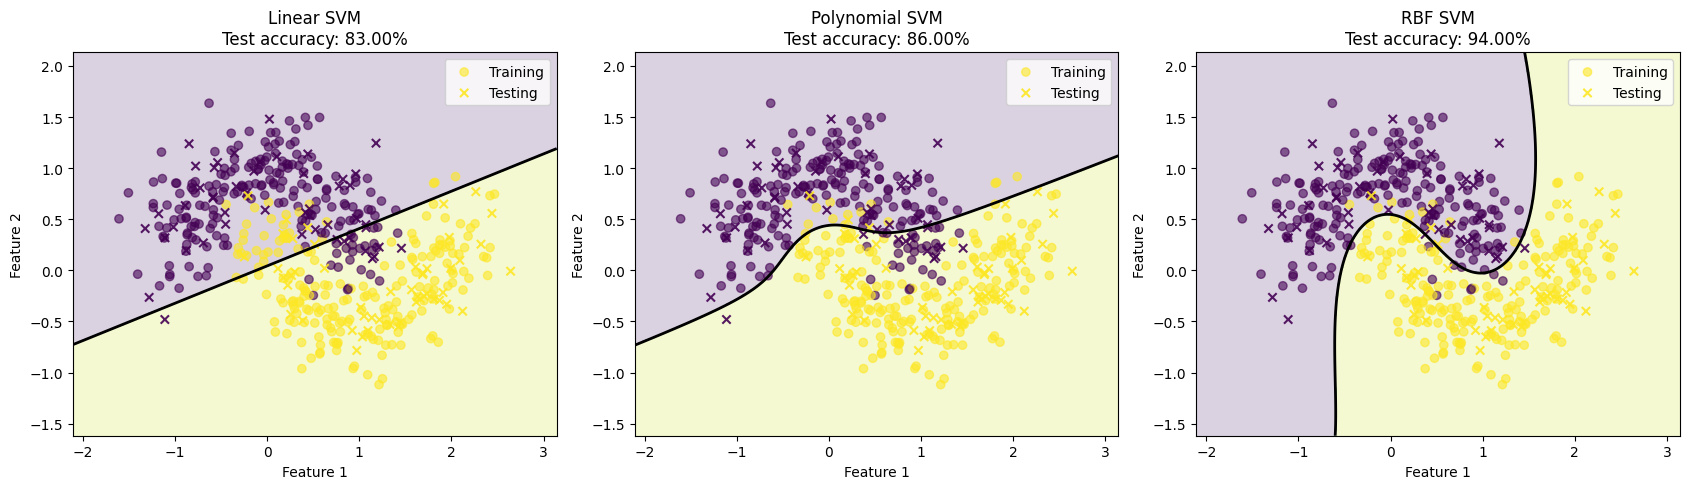

In [59]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt
import time

# Define the three kernel models
kernel_models = {
    "Linear SVM": SVC(kernel="linear", C=1.0),
    "Polynomial SVM": SVC(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "RBF SVM": SVC(kernel="rbf", C=1.0, gamma="scale")
}

# Train each model and evaluate it
kernel_results = {}

for name, model in kernel_models.items():
    start = time.perf_counter()
    model.fit(X_moons_train, y_moons_train)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_moons_test)
    accuracy = accuracy_score(y_moons_test, predictions)

    kernel_results[name] = {
        "model": model,
        "accuracy": accuracy,
        "training_time": train_time
    }

    print(
        f"{name}: "
        f"Accuracy = {accuracy:.4f}, "
        f"Training time = {train_time:.6f} seconds"
    )

# Create a grid for plotting decision boundaries
x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = np.c_[xx.ravel(), yy.ravel()]

# Plot each kernel's decision boundary
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, result) in zip(axes, kernel_results.items()):
    model = result["model"]
    grid_predictions = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, grid_predictions, alpha=0.2)
    ax.contour(
        xx, yy,
        model.decision_function(grid).reshape(xx.shape),
        levels=[0],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        X_moons_train[:, 0],
        X_moons_train[:, 1],
        c=y_moons_train,
        marker="o",
        alpha=0.6,
        label="Training"
    )

    ax.scatter(
        X_moons_test[:, 0],
        X_moons_test[:, 1],
        c=y_moons_test,
        marker="x",
        alpha=0.9,
        label="Testing"
    )

    ax.set_title(
        f"{name}\nTest accuracy: {result['accuracy']:.2%}"
    )
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()

plt.tight_layout()
plt.show()


In [60]:


plt.gcf().savefig(
    "part_c_kernel_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved: part_c_kernel_comparison.png")


Saved: part_c_kernel_comparison.png


<Figure size 640x480 with 0 Axes>

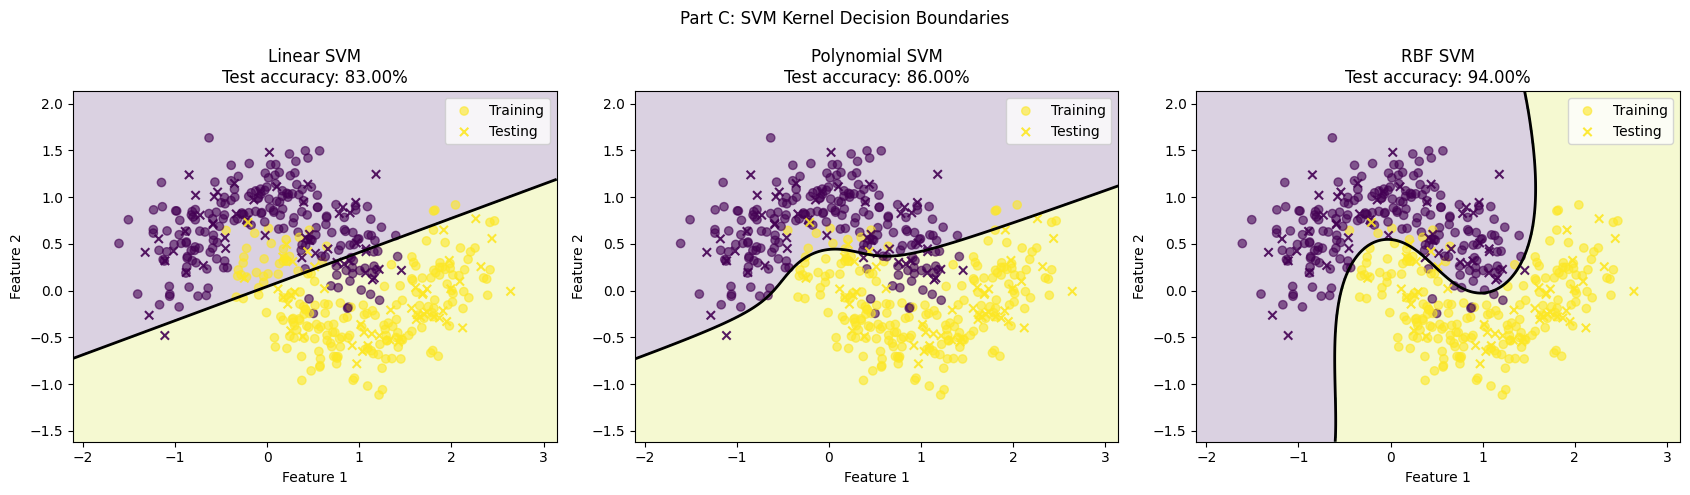

Saved kernel comparison with all three plots.


In [61]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, result) in zip(axes, kernel_results.items()):
    model = result["model"]

    grid_predictions = model.predict(grid).reshape(xx.shape)
    grid_scores = model.decision_function(grid).reshape(xx.shape)

    ax.contourf(xx, yy, grid_predictions, alpha=0.2)
    ax.contour(
        xx, yy, grid_scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        X_moons_train[:, 0], X_moons_train[:, 1],
        c=y_moons_train, marker="o", alpha=0.6,
        label="Training"
    )
    ax.scatter(
        X_moons_test[:, 0], X_moons_test[:, 1],
        c=y_moons_test, marker="x", alpha=0.9,
        label="Testing"
    )

    ax.set_title(
        f"{name}\nTest accuracy: {result['accuracy']:.2%}"
    )
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()

fig.suptitle("Part C: SVM Kernel Decision Boundaries")
fig.tight_layout()

fig.savefig(
    "part_c_kernel_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print("Saved kernel comparison with all three plots.")


In [62]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# All four banknote features
X_full = df[
    ["Variance", "Skewness", "Curtosis", "Entropy"]
].to_numpy(dtype=float)

y_full = df["Class"].to_numpy()

# Consistent train-test split
X_train_full, X_test_full, y_train_full, y_test_full = (
    train_test_split(
        X_full,
        y_full,
        test_size=0.2,
        random_state=42,
        stratify=y_full
    )
)

# Scale only for SVM models
scaler_full = StandardScaler()
X_train_full_scaled = scaler_full.fit_transform(X_train_full)
X_test_full_scaled = scaler_full.transform(X_test_full)

# Labels for manual SVM
y_train_full_svm = np.where(y_train_full == 0, -1, 1)
y_test_full_svm = np.where(y_test_full == 0, -1, 1)

print("Full dataset:", X_full.shape)
print("Training set:", X_train_full.shape)
print("Testing set:", X_test_full.shape)
print("Features:", ["Variance", "Skewness", "Curtosis", "Entropy"])
print("Classes:", np.unique(y_train_full))


Full dataset: (1372, 4)
Training set: (1097, 4)
Testing set: (275, 4)
Features: ['Variance', 'Skewness', 'Curtosis', 'Entropy']
Classes: [0 1]


In [64]:

import inspect

print("predict_tree function:")
print(inspect.signature(predict_tree))
print(inspect.getsource(predict_tree))

print("\npredict_one function:")
print(inspect.signature(predict_one))
print(inspect.getsource(predict_one))

print("\nManual tree type:", type(manual_tree_full))
print("Manual tree structure:", manual_tree_full)
print("One test sample:", X_test_full[0])
print("One test sample shape:", X_test_full[0].shape)


predict_tree function:
(tree, X)
def predict_tree(tree, X):
    
    predictions = []

    for sample in X:
        prediction = predict_one(tree, sample)
        predictions.append(prediction)

    return np.array(predictions)


predict_one function:
(node, sample)
def predict_one(node, sample):
    
    if node["feature"] is None:
        return node["prediction"]

  
    feature = node["feature"]
    threshold = node["threshold"]

    if sample[feature] <= threshold:
        return predict_one(node["left"], sample)
    else:
        return predict_one(node["right"], sample)


Manual tree type: <class 'dict'>
Manual tree structure: {'prediction': np.int64(0), 'feature': 0, 'threshold': np.float64(0.7651), 'left': {'prediction': np.int64(1), 'feature': 1, 'threshold': np.float64(5.1608), 'left': {'prediction': np.int64(1), 'feature': 0, 'threshold': np.float64(-0.458565), 'left': {'prediction': np.int64(1), 'feature': 2, 'threshold': np.float64(6.21865), 'left': {'prediction': np.int6

In [65]:

manual_tree_pred = predict_tree(manual_tree_full, X_test_full)

print("Number of predictions:", len(manual_tree_pred))
print("Number of test samples:", len(y_test_full))
print("Manual Decision Tree Accuracy:",
      round(accuracy_score(y_test_full, manual_tree_pred), 4))


Number of predictions: 275
Number of test samples: 275
Manual Decision Tree Accuracy: 0.9855


In [67]:

import time
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

# Measure manual tree prediction time
start = time.perf_counter()
manual_tree_pred = predict_tree(manual_tree_full, X_test_full)
manual_tree_prediction_time = time.perf_counter() - start

# Train sklearn tree if it has not been trained yet
sklearn_tree_full = DecisionTreeClassifier(
    criterion="entropy", max_depth=5, random_state=42
)

start = time.perf_counter()
sklearn_tree_full.fit(X_train_full, y_train_full)
sklearn_tree_train_time = time.perf_counter() - start

# Measure sklearn prediction time
start = time.perf_counter()
sklearn_tree_pred = sklearn_tree_full.predict(X_test_full)
sklearn_tree_prediction_time = time.perf_counter() - start

# Results
print("MANUAL DECISION TREE")
print("Accuracy:", round(accuracy_score(y_test_full, manual_tree_pred), 4))
print("Training time:", round(manual_tree_train_time, 6), "seconds")
print("Prediction time:", round(manual_tree_prediction_time, 6), "seconds")

print("\nSCIKIT-LEARN DECISION TREE")
print("Accuracy:", round(accuracy_score(y_test_full, sklearn_tree_pred), 4))
print("Training time:", round(sklearn_tree_train_time, 6), "seconds")
print("Prediction time:", round(sklearn_tree_prediction_time, 6), "seconds")

print("\nPredictions identical:",
      np.array_equal(manual_tree_pred, sklearn_tree_pred))


MANUAL DECISION TREE
Accuracy: 0.9855
Training time: 1.64507 seconds
Prediction time: 0.001033 seconds

SCIKIT-LEARN DECISION TREE
Accuracy: 0.9855
Training time: 0.008001 seconds
Prediction time: 0.000879 seconds

Predictions identical: True


In [68]:



manual_svm_full_w, manual_svm_full_b, manual_svm_full_losses, manual_svm_full_train_time = train_linear_svm(
    X_train_full_scaled,
    y_train_full_svm,
    C=1.0,
    learning_rate=0.01,
    n_iterations=1000
)

start = time.perf_counter()
manual_svm_full_scores = (
    X_test_full_scaled @ manual_svm_full_w + manual_svm_full_b
)
manual_svm_full_pred = np.where(manual_svm_full_scores >= 0, 1, -1)
manual_svm_full_prediction_time = time.perf_counter() - start


manual_svm_full_pred_labels = np.where(manual_svm_full_pred == -1, 0, 1)

print("Manual Linear SVM — Four Features")
print("Weights:", manual_svm_full_w)
print("Bias:", round(manual_svm_full_b, 4))
print("Accuracy:", round(
    accuracy_score(y_test_full, manual_svm_full_pred_labels), 4
))
print("Training time:", round(manual_svm_full_train_time, 6), "seconds")
print("Prediction time:", round(manual_svm_full_prediction_time, 6), "seconds")


Manual Linear SVM — Four Features
Weights: [-0.50642338 -0.27240004 -0.0293158  -0.03014723]
Bias: -0.267
Accuracy: 0.8836
Training time: 0.345767 seconds
Prediction time: 0.000303 seconds


In [69]:

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import time


sklearn_svm_full = LinearSVC(
    C=1.0,
    max_iter=10000,
    random_state=42
)


start = time.perf_counter()
sklearn_svm_full.fit(X_train_full_scaled, y_train_full)
sklearn_svm_full_train_time = time.perf_counter() - start

start = time.perf_counter()
sklearn_svm_full_pred = sklearn_svm_full.predict(X_test_full_scaled)
sklearn_svm_full_prediction_time = time.perf_counter() - start

print("SCIKIT-LEARN LINEAR SVM — FOUR FEATURES")
print("Accuracy:", round(accuracy_score(y_test_full, sklearn_svm_full_pred), 4))
print("Precision:", round(precision_score(y_test_full, sklearn_svm_full_pred), 4))
print("Recall:", round(recall_score(y_test_full, sklearn_svm_full_pred), 4))
print("F1-score:", round(f1_score(y_test_full, sklearn_svm_full_pred), 4))
print("Training time:", round(sklearn_svm_full_train_time, 6), "seconds")
print("Prediction time:", round(sklearn_svm_full_prediction_time, 6), "seconds")


SCIKIT-LEARN LINEAR SVM — FOUR FEATURES
Accuracy: 0.9855
Precision: 0.9683
Recall: 1.0
F1-score: 0.9839
Training time: 0.010246 seconds
Prediction time: 0.000701 seconds


In [70]:

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import time

# Create RBF SVM
rbf_svm_full = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

# Measure training time
start = time.perf_counter()
rbf_svm_full.fit(X_train_full_scaled, y_train_full)
rbf_svm_full_train_time = time.perf_counter() - start

# Measure prediction time
start = time.perf_counter()
rbf_svm_full_pred = rbf_svm_full.predict(X_test_full_scaled)
rbf_svm_full_prediction_time = time.perf_counter() - start

# Evaluation
print("RBF SVM — FOUR FEATURES")
print("Accuracy:", round(accuracy_score(y_test_full, rbf_svm_full_pred), 4))
print("Precision:", round(precision_score(y_test_full, rbf_svm_full_pred), 4))
print("Recall:", round(recall_score(y_test_full, rbf_svm_full_pred), 4))
print("F1-score:", round(f1_score(y_test_full, rbf_svm_full_pred), 4))
print("Training time:", round(rbf_svm_full_train_time, 6), "seconds")
print("Prediction time:", round(rbf_svm_full_prediction_time, 6), "seconds")


RBF SVM — FOUR FEATURES
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
Training time: 0.020933 seconds
Prediction time: 0.003096 seconds


In [71]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Converting manual SVM predictions from -1/+1 to 0/1
manual_svm_labels = np.where(manual_svm_full_pred == -1, 0, 1)

model_results = [
    {
        "Model": "Manual Decision Tree",
        "y_pred": manual_tree_pred,
        "train_time": manual_tree_train_time,
        "prediction_time": manual_tree_prediction_time
    },
    {
        "Model": "Scikit-learn Decision Tree",
        "y_pred": sklearn_tree_pred,
        "train_time": sklearn_tree_train_time,
        "prediction_time": sklearn_tree_prediction_time
    },
    {
        "Model": "Manual Linear SVM",
        "y_pred": manual_svm_labels,
        "train_time": manual_svm_full_train_time,
        "prediction_time": manual_svm_full_prediction_time
    },
    {
        "Model": "Scikit-learn Linear SVM",
        "y_pred": sklearn_svm_full_pred,
        "train_time": sklearn_svm_full_train_time,
        "prediction_time": sklearn_svm_full_prediction_time
    },
    {
        "Model": "RBF SVM",
        "y_pred": rbf_svm_full_pred,
        "train_time": rbf_svm_full_train_time,
        "prediction_time": rbf_svm_full_prediction_time
    }
]

rows = []

for result in model_results:
    y_pred = result["y_pred"]

    rows.append({
        "Model": result["Model"],
        "Accuracy": accuracy_score(y_test_full, y_pred),
        "Precision": precision_score(y_test_full, y_pred, zero_division=0),
        "Recall": recall_score(y_test_full, y_pred, zero_division=0),
        "F1-score": f1_score(y_test_full, y_pred, zero_division=0),
        "Training Time (s)": result["train_time"],
        "Prediction Time (s)": result["prediction_time"]
    })

comparison_df = pd.DataFrame(rows)

# Display rounded results
display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9855,0.9758,0.9918,0.9837,1.6451,0.0010
1,Scikit-learn Decision Tree,0.9855,0.9758,0.9918,0.9837,0.0080,0.0009
2,Manual Linear SVM,0.8836,0.9412,0.7869,0.8571,0.3458,0.0003
3,Scikit-learn Linear SVM,0.9855,0.9683,1.0000,0.9839,0.0102,0.0007
4,RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0209,0.0031


### Part D: Final Model Comparison and Discussion

All five models were evaluated on the same Banknote Authentication dataset using the same 80:20 train-test split and `random_state=42`. The Decision Trees used all four original features, while the SVM models used standardized features.

**1. Model performance**

The RBF SVM achieved the best results, with 100% accuracy, precision, recall, and F1-score on the test set. The Scikit-learn Linear SVM achieved 98.55% accuracy and an F1-score of 0.9839. Both Decision Tree implementations achieved 98.55% accuracy and an F1-score of 0.9837.

The manual Linear SVM achieved 88.36% accuracy, lower than the other models. This suggests that its current gradient-descent implementation and settings may need further tuning.

**2. Manual versus Scikit-learn implementations**

The manual and Scikit-learn Decision Trees achieved identical predictions and the same accuracy of 98.55%. However, Scikit-learn trained much faster: approximately 0.008 seconds compared with 1.645 seconds for the manual implementation.

The Scikit-learn Linear SVM also substantially outperformed the manual Linear SVM in this experiment. Optimized library implementations are generally faster and provide mature numerical optimization routines.

**3. Training and prediction time**

The Scikit-learn Decision Tree had the shortest measured training time among these five models. The RBF SVM took approximately 0.021 seconds to train and 0.003 seconds to predict the test samples. These timings are specific to this run and may vary with the computing environment.

**4. Interpretability and model complexity**

Decision Trees are relatively easy to interpret because their predictions can be explained through feature-based split rules. Linear SVMs learn a linear decision boundary, while an RBF SVM can learn nonlinear boundaries and represent more complex relationships.

**5. Feature scaling and overfitting**

Feature scaling is important for SVMs because feature magnitudes influence the optimization process and distances used by the kernel. Decision Trees generally do not require feature scaling.

Although the RBF SVM achieved perfect test-set performance, this result does not guarantee perfect generalization to unseen data. Cross-validation and evaluation on genuinely unseen data would provide stronger evidence of generalization.

**Conclusion:** The RBF SVM performed best on this test split, while the Scikit-learn Decision Tree offered strong accuracy, interpretability, and fast training. The experiment also demonstrated why manually implementing machine-learning algorithms is useful for understanding their underlying mechanics.